# Deep Learning Mini Project: Predicting Millionaire Status from Behavioral Habits
**Course**: Deep Learning (Semester 5)  
**Dataset**: Millionaire Habits Dataset (`Millionaire_Habits_Dataset.csv`)  
**Target Feature**: `millionaire_status` (Binary Classification: $y \in \{0, 1\}$)  
**Guidelines**: Aligned with lecture instructions (`Instruction_from_lecture.pdf`)

---

## 👥 Slide 1 & 2: Group Identity & Job Distribution

### Group Members (Slide 1)
| No | Name | Student ID (NIM) | Role in Group |
|:---|:---|:---|:---|
| 1 | [Student 1 Name] | [NIM 1] | Project Lead & Neural Network Architecture Design |
| 2 | [Student 2 Name] | [NIM 2] | Data Engineering, Anti-Leakage & Preprocessing |
| 3 | [Student 3 Name] | [NIM 3] | Training Strategy & Hyperparameter Tuning |
| 4 | [Student 4 Name] | [NIM 4] | Evaluation, Ablation Study & Model Interpretability |
| 5 | [Student 5 Name] (Optional) | [NIM 5] | Presentation Deck & Documentation |

### Job Descriptions (Slide 2)
- **Data Engineering**: Data audit, dropping direct wealth/balance sheet leakage columns, missingness imputation, categorical encoding, and stratified splitting.
- **Architecture Design**: PyTorch implementation of Baseline MLP, Deep Regularized MLP (BatchNorm + Dropout), and Tabular ResNet (Skip Connections).
- **Optimization & Tuning**: Implementing BCEWithLogitsLoss, AdamW/SGD/RMSprop comparison, Cosine Annealing LR scheduling, and parameter tuning.
- **Evaluation & Explainability**: Multi-metric evaluation (Accuracy, F1, ROC-AUC), learning curves, 5-Fold Cross Validation, and Permutation Feature Importance.
- **Reporting**: Slide deck synthesis and slide asset generation.


## 🎯 Slide 3: Problem Case Formulation

### Background & Research Objective
The goal is to determine whether **lifestyle, daily habits, financial behaviors, education, and career traits** can accurately predict whether an individual achieves millionaire status (`millionaire_status = 1`).

### Critical Scientific Principle: Zero Data Leakage
In the synthetic dataset, `millionaire_status` was algorithmically defined as $\text{net\_worth} \ge \$1,000,000$.
- Including direct wealth columns (e.g. `net_worth`, `total_assets`, `stocks_value`, `checking_savings`, `total_liabilities`) causes **trivial target leakage** ($\approx 100\%$ accuracy by arithmetic identity).
- **Scientific Solution**: We strictly exclude all 35 balance-sheet asset/liability columns and target derivatives. The model is trained purely on **236 behavioral, habit, demographic, and career features**.

This formulates a genuine predictive machine learning task: **Can your habits predict your financial destiny?**


## ⚙️ 1. Environment Setup & Reproducibility
We configure random seeds across Python, NumPy, and PyTorch to guarantee strict reproducibility.


In [1]:
import os
import random
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

warnings.filterwarnings('ignore')

# Set random seeds for exact reproducibility
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Version: {torch.__version__}")
print(f"Compute Device: {device}")

# Create output folder for presentation slide figures
os.makedirs('slides_export', exist_ok=True)


PyTorch Version: 2.12.0+cpu
Compute Device: cpu


## 📊 Slide 4: Dataset Overview, Anti-Leakage & Preprocessing Pipeline

### Data Architecture
- Total observations: $100,000$ individuals
- Total initial columns: $274$
- Target variable: `millionaire_status` (Binary: 0 = Non-Millionaire, 1 = Millionaire)

### Preprocessing Strategy:
1. **Target Separation**: Extract `millionaire_status`.
2. **Anti-Leakage Removal**: Remove metadata (`synthetic_person_id`, etc.), balance sheet items (`E. Wealth`), and direct derived targets (`Q. Target/ML Columns`).
3. **Missing Value Imputation**: Median imputation for numerical features; constant `'Missing'` imputation for categorical features.
4. **Categorical Encoding**: One-Hot Encoding with `handle_unknown='ignore'`.
5. **Feature Standardization**: Z-score standardization ($z = \frac{x - \mu}{\sigma}$) fit strictly on training set.


In [2]:
# 1. Load Dataset & Data Dictionary
data_path = 'Millionaire_Habits_Dataset.csv'
dict_path = 'Millionaire_Habits_Data_Dictionary.csv'

df = pd.read_csv(data_path)
dict_df = pd.read_csv(dict_path)

print(f"Raw Dataset Shape: {df.shape}")

# 2. Identify Leakage & Non-Feature Columns
leakage_categories = ['E. Wealth', 'Q. Target/ML Columns']
leak_cols = dict_df[dict_df['category'].isin(leakage_categories)]['column_name'].tolist()
meta_cols = ['synthetic_person_id', 'dataset_version', 'generation_seed']

# Columns to drop (excluding our target variable)
cols_to_drop = [c for c in (leak_cols + meta_cols) if c != 'millionaire_status' and c in df.columns]
print(f"Identified {len(cols_to_drop)} leakage and metadata columns to drop.")

# 3. Separate Features X and Target y
X_df = df.drop(columns=cols_to_drop + ['millionaire_status'])
y = df['millionaire_status'].values.astype(np.float32)

print(f"Feature Matrix Shape (X): {X_df.shape}")
print(f"Target Vector Shape (y): {y.shape}")

# Target class balance
counts = pd.Series(y).value_counts().sort_index()
proportions = pd.Series(y).value_counts(normalize=True).sort_index()
print("\nTarget Class Distribution:")
for cls in [0, 1]:
    lbl = 'Non-Millionaire (0)' if cls == 0 else 'Millionaire (1)'
    print(f"  {lbl}: {int(counts[cls]):,} samples ({proportions[cls]*100:.2f}%)")


Raw Dataset Shape: (100000, 274)
Identified 37 leakage and metadata columns to drop.
Feature Matrix Shape (X): (100000, 236)
Target Vector Shape (y): (100000,)

Target Class Distribution:
  Non-Millionaire (0): 57,508 samples (57.51%)
  Millionaire (1): 42,492 samples (42.49%)


In [3]:
# 4. Define Preprocessing Pipeline
num_cols = X_df.select_dtypes(include=['number']).columns.tolist()
cat_cols = X_df.select_dtypes(exclude=['number']).columns.tolist()

print(f"Numerical features: {len(num_cols)}")
print(f"Categorical features: {len(cat_cols)}")

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ]
)


Numerical features: 196
Categorical features: 40


### Train / Validation / Test Splitting Protocol
To ensure rigorous evaluation without data leakage:
- **Training Set (80%)**: $80,000$ samples (for network optimization)
- **Validation Set (10%)**: $10,000$ samples (for model selection and early stopping)
- **Test Set (10%)**: $10,000$ samples (strictly held out for final benchmarking)
- **Stratification**: Guaranteed identical target proportion ($42.5\%$ positive class) across all splits.


In [4]:
# Stratified 80% Train, 10% Val, 10% Test
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X_df, y, test_size=0.20, random_state=SEED, stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

# Fit preprocessor on training data ONLY
X_train = preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_val = preprocessor.transform(X_val_raw).astype(np.float32)
X_test = preprocessor.transform(X_test_raw).astype(np.float32)

input_dim = X_train.shape[1]
print(f"Final Preprocessed Feature Dimension: {input_dim}")
print(f"Training Set:   {X_train.shape[0]:,} samples")
print(f"Validation Set: {X_val.shape[0]:,} samples")
print(f"Test Set:       {X_test.shape[0]:,} samples")

# PyTorch Dataset & DataLoader
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 512

train_loader = DataLoader(TabularDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TabularDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TabularDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)


Final Preprocessed Feature Dimension: 531
Training Set:   80,000 samples
Validation Set: 10,000 samples
Test Set:       10,000 samples


## 🧠 Slide 5: Neural Network Architecture Implementations

We design, implement, and benchmark **three distinct neural network architectures** to tackle tabular binary classification:

1. **Model 1: Baseline Shallow Multi-Layer Perceptron (MLP)**
   - Classic feedforward architecture without modern normalization.
   - Layers: $\text{Input}(D) \to 128 \to 64 \to 1$.
   - Activation: ReLU.
   
2. **Model 2: Deep Regularized Multi-Layer Perceptron**
   - 4-layer deep architecture with modern regularization.
   - Batch Normalization (`BatchNorm1d`) after each linear layer to accelerate training and mitigate internal covariate shift.
   - Dropout ($p=0.25, 0.2, 0.1$) to prevent overfitting.
   - Layers: $\text{Input}(D) \to 256 \to 128 \to 64 \to 32 \to 1$.

3. **Model 3: Modern Tabular ResNet (Residual Network)**
   - Employs residual skip-connections ($x_{l+1} = \sigma(x_l + \mathcal{F}(x_l))$) designed specifically for tabular representations (inspired by Gorishniy et al., NeurIPS 2021).
   - Utilizes Gaussian Error Linear Units (`GELU`) and layer-wise residual blocks.
   - Preserves feature gradients across deep layers.


In [5]:
# 1. Baseline Shallow MLP
class BaselineMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        return self.net(x)

# 2. Deep Regularized MLP (BatchNorm + Dropout)
class DeepRegularizedMLP(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout_rate * 0.8),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout_rate * 0.5),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.net(x)

# 3. Tabular ResNet with Residual Skip Connections
class TabularResBlock(nn.Module):
    def __init__(self, in_features, out_features, dropout_rate=0.2):
        super().__init__()
        self.block = nn.Sequential(
            nn.BatchNorm1d(in_features),
            nn.Linear(in_features, out_features),
            nn.GELU(),
            nn.Dropout(dropout_rate),
            nn.BatchNorm1d(out_features),
            nn.Linear(out_features, out_features),
            nn.Dropout(dropout_rate)
        )
        self.shortcut = nn.Linear(in_features, out_features) if in_features != out_features else nn.Identity()
        self.act = nn.GELU()
        
    def forward(self, x):
        return self.act(self.shortcut(x) + self.block(x))

class TabularResNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout_rate=0.2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU()
        )
        self.res1 = TabularResBlock(hidden_dim, hidden_dim, dropout_rate)
        self.res2 = TabularResBlock(hidden_dim, hidden_dim // 2, dropout_rate)
        self.res3 = TabularResBlock(hidden_dim // 2, hidden_dim // 2, dropout_rate)
        self.head = nn.Sequential(
            nn.BatchNorm1d(hidden_dim // 2),
            nn.Linear(hidden_dim // 2, 1)
        )
        
    def forward(self, x):
        x = self.stem(x)
        x = self.res1(x)
        x = self.res2(x)
        x = self.res3(x)
        return self.head(x)

# Parameter Counts
for name, model_cls in [("Baseline MLP", lambda: BaselineMLP(input_dim)),
                        ("Deep Regularized MLP", lambda: DeepRegularizedMLP(input_dim)),
                        ("Tabular ResNet", lambda: TabularResNet(input_dim))]:
    m = model_cls()
    params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{name:22s} | Trainable Parameters: {params:,}")


Baseline MLP           | Trainable Parameters: 76,417
Deep Regularized MLP   | Trainable Parameters: 180,417
Tabular ResNet         | Trainable Parameters: 386,305


## ⚡ Slide 6: Learning Strategy & Parameter Tuning

### Optimization Strategy:
- **Loss Function**: Binary Cross-Entropy with Logits (`nn.BCEWithLogitsLoss`) with numerical stability via log-sum-exp trick:
  $$\mathcal{L}(y, \hat{y}) = -\left[ y \cdot \log \sigma(\hat{y}) + (1 - y) \cdot \log(1 - \sigma(\hat{y})) \right]$$
- **Optimizer**: AdamW (Decoupled Weight Decay) vs. SGD with Nesterov Momentum vs. RMSprop.
- **Learning Rate Scheduler**: Cosine Annealing (`CosineAnnealingLR`):
  $$\eta_t = \eta_{min} + \frac{1}{2}(\eta_{max} - \eta_{min})\left(1 + \cos\left(\frac{t}{T_{max}}\pi\right)\right)$$
- **Early Stopping**: Monitored on validation loss to prevent overfitting.


In [6]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * len(y_batch)
        preds = (torch.sigmoid(logits) >= 0.5).float()
        correct += (preds == y_batch).sum().item()
        total += len(y_batch)
        
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    y_true, y_pred, y_prob = [], [], []
    
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()
        
        total_loss += loss.item() * len(y_batch)
        y_true.extend(y_batch.cpu().numpy().flatten())
        y_pred.extend(preds.cpu().numpy().flatten())
        y_prob.extend(probs.cpu().numpy().flatten())
        
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)
    
    metrics = {
        'loss': total_loss / len(y_true),
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_prob),
        'pr_auc': average_precision_score(y_true, y_prob),
        'y_true': y_true,
        'y_pred': y_pred,
        'y_prob': y_prob
    }
    return metrics

def fit_model(model, train_loader, val_loader, optimizer, scheduler=None, epochs=15, device=device):
    criterion = nn.BCEWithLogitsLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    best_val_loss = float('inf')
    best_weights = None
    
    start_time = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        val_metrics = evaluate(model, val_loader, criterion, device)
        
        if scheduler is not None:
            scheduler.step()
            
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(val_metrics['loss'])
        history['val_acc'].append(val_metrics['accuracy'])
        
        if val_metrics['loss'] < best_val_loss:
            best_val_loss = val_metrics['loss']
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            
    elapsed = time.time() - start_time
    # Restore best checkpoint
    if best_weights is not None:
        model.load_state_dict(best_weights)
        
    return history, elapsed


## 🔬 Slide 7: Experiment 1 - Multi-Model Architecture Benchmark

We train all 3 neural network architectures under controlled conditions:
- **Optimizer**: AdamW (Learning Rate $= 10^{-3}$, Weight Decay $= 10^{-4}$)
- **LR Scheduler**: Cosine Annealing ($T_{max} = 15$)
- **Epochs**: 15


In [7]:
EPOCHS = 15
architectures = {
    'Baseline MLP': BaselineMLP(input_dim),
    'Deep Regularized MLP': DeepRegularizedMLP(input_dim, dropout_rate=0.2),
    'Tabular ResNet': TabularResNet(input_dim, hidden_dim=256, dropout_rate=0.2)
}

histories = {}
trained_models = {}
benchmark_results = []

criterion = nn.BCEWithLogitsLoss()

print(f"{'Architecture':22s} | {'Time (s)':8s} | {'Val Acc':8s} | {'Val Loss':8s} | {'Test Acc':8s} | {'Test F1':8s} | {'Test ROC-AUC':12s}")
print("-" * 88)

for name, model in architectures.items():
    seed_everything(SEED)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    
    hist, duration = fit_model(model, train_loader, val_loader, optimizer, scheduler, epochs=EPOCHS, device=device)
    histories[name] = hist
    trained_models[name] = model
    
    val_res = evaluate(model, val_loader, criterion, device)
    test_res = evaluate(model, test_loader, criterion, device)
    
    benchmark_results.append({
        'Model': name,
        'Train Time (s)': round(duration, 2),
        'Val Accuracy': round(val_res['accuracy'], 4),
        'Val Loss': round(val_res['loss'], 4),
        'Test Accuracy': round(test_res['accuracy'], 4),
        'Test Precision': round(test_res['precision'], 4),
        'Test Recall': round(test_res['recall'], 4),
        'Test F1-Score': round(test_res['f1'], 4),
        'Test ROC-AUC': round(test_res['roc_auc'], 4),
        'Test PR-AUC': round(test_res['pr_auc'], 4),
        'y_test_pred': test_res['y_pred'],
        'y_test_prob': test_res['y_prob']
    })
    
    print(f"{name:22s} | {duration:8.2f} | {val_res['accuracy']:8.4f} | {val_res['loss']:8.4f} | {test_res['accuracy']:8.4f} | {test_res['f1']:8.4f} | {test_res['roc_auc']:12.4f}")

benchmark_df = pd.DataFrame(benchmark_results).drop(columns=['y_test_pred', 'y_test_prob'])
benchmark_df.to_csv('slides_export/model_benchmark_table.csv', index=False)


Architecture           | Time (s) | Val Acc  | Val Loss | Test Acc | Test F1  | Test ROC-AUC
----------------------------------------------------------------------------------------


Baseline MLP           |    10.54 |   0.9649 |   0.0819 |   0.9637 |   0.9576 |       0.9957


Deep Regularized MLP   |    20.16 |   0.9611 |   0.0925 |   0.9599 |   0.9532 |       0.9947


Tabular ResNet         |    39.84 |   0.9576 |   0.0985 |   0.9570 |   0.9496 |       0.9938


## 📈 Slide 8: Learning Curves, ROC Curves & Confusion Matrices

We plot and analyze:
1. **Training & Validation Loss Curves** (checking convergence & overfitting).
2. **Validation Accuracy Curves** across epochs.
3. **Receiver Operating Characteristic (ROC)** & **Precision-Recall (PR)** Curves.
4. **Confusion Matrices** for the models on the held-out test set ($N=10,000$).


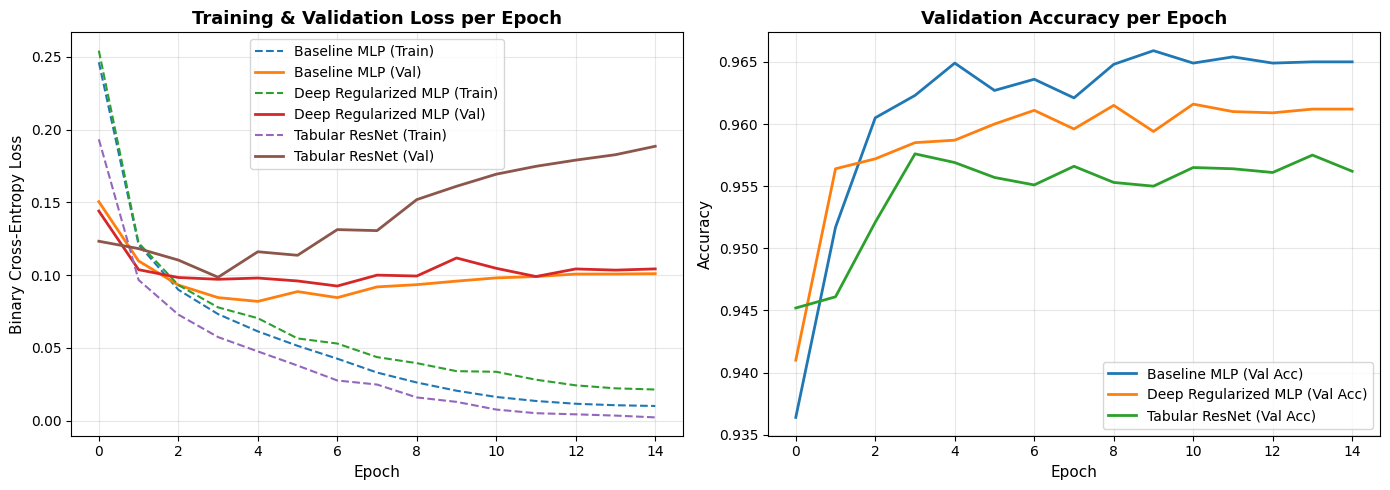

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss curves
for name in histories:
    axes[0].plot(histories[name]['train_loss'], label=f"{name} (Train)", linestyle='--')
    axes[0].plot(histories[name]['val_loss'], label=f"{name} (Val)", linewidth=2)
axes[0].set_title("Training & Validation Loss per Epoch", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot 2: Accuracy curves
for name in histories:
    axes[1].plot(histories[name]['val_acc'], label=f"{name} (Val Acc)", linewidth=2)
axes[1].set_title("Validation Accuracy per Epoch", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig('slides_export/slide8_learning_curves.png', dpi=300)
plt.show()


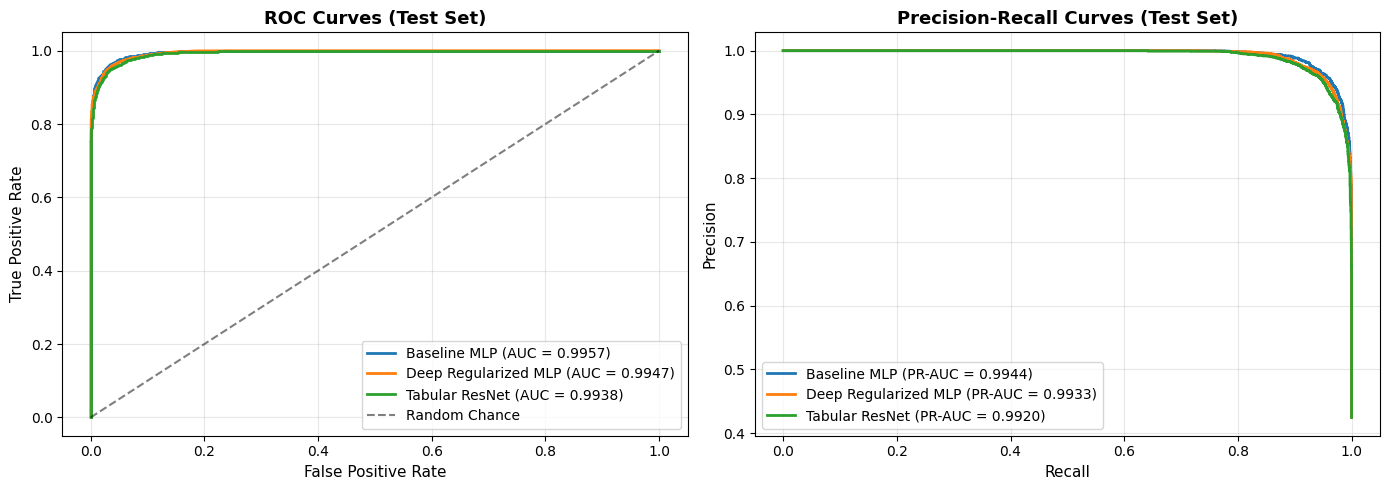

In [9]:
# ROC and PR Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for res in benchmark_results:
    fpr, tpr, _ = roc_curve(y_test, res['y_test_prob'])
    prec, rec, _ = precision_recall_curve(y_test, res['y_test_prob'])
    axes[0].plot(fpr, tpr, label=f"{res['Model']} (AUC = {res['Test ROC-AUC']:.4f})", linewidth=2)
    axes[1].plot(rec, prec, label=f"{res['Model']} (PR-AUC = {res['Test PR-AUC']:.4f})", linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance')
axes[0].set_title("ROC Curves (Test Set)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate", fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='lower right')

axes[1].set_title("Precision-Recall Curves (Test Set)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.savefig('slides_export/slide8_roc_pr_curves.png', dpi=300)
plt.show()


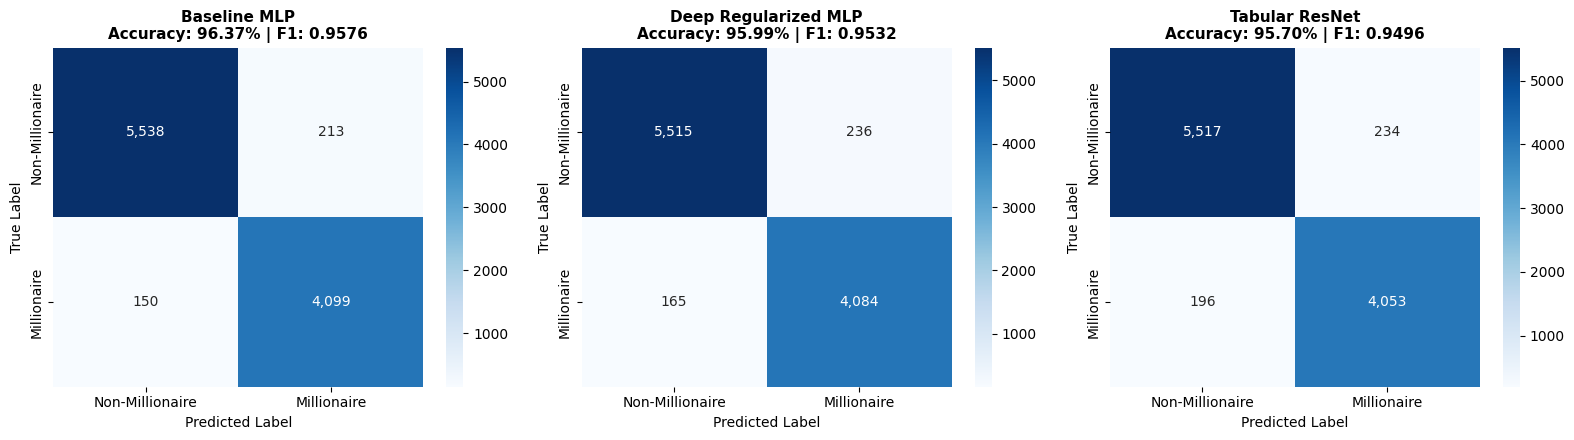

In [10]:
# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, res in enumerate(benchmark_results):
    cm = confusion_matrix(y_test, res['y_test_pred'])
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[idx],
                xticklabels=['Non-Millionaire', 'Millionaire'],
                yticklabels=['Non-Millionaire', 'Millionaire'])
    axes[idx].set_title(f"{res['Model']}\nAccuracy: {res['Test Accuracy']*100:.2f}% | F1: {res['Test F1-Score']:.4f}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.tight_layout()
plt.savefig('slides_export/slide7_confusion_matrices.png', dpi=300)
plt.show()


## 🔍 Slide 9: Experiment 2 - Learning Strategies & Hyperparameter Tuning

We conduct comprehensive parameter ablation studies on the top-performing architecture:
1. **Optimizer Comparison**: AdamW vs. SGD (with Nesterov momentum 0.9) vs. RMSprop.
2. **Learning Rate Sensitivity**: $\eta \in \{10^{-4}, 10^{-3}, 5 \times 10^{-3}\}$.
3. **Dropout Regularization**: $p \in \{0.1, 0.25, 0.4\}$.
4. **Stratified 5-Fold Cross-Validation**: Statistical confidence intervals (Mean $\pm$ Std) on the champion model.


In [11]:
# 1. Optimizer Comparison on Tabular ResNet
opt_experiments = {}
optimizers_dict = {
    'AdamW': lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=1e-4),
    'SGD (Mom=0.9)': lambda p: torch.optim.SGD(p, lr=1e-2, momentum=0.9, weight_decay=1e-4, nesterov=True),
    'RMSprop': lambda p: torch.optim.RMSprop(p, lr=1e-3, weight_decay=1e-4)
}

print(f"{'Optimizer':15s} | {'Val Acc':8s} | {'Test Acc':8s} | {'Test F1':8s} | {'Test ROC-AUC':12s}")
print("-" * 60)

for opt_name, opt_fn in optimizers_dict.items():
    seed_everything(SEED)
    m = TabularResNet(input_dim, hidden_dim=256, dropout_rate=0.2).to(device)
    opt = opt_fn(m.parameters())
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)
    fit_model(m, train_loader, val_loader, opt, sched, epochs=10, device=device)
    
    val_m = evaluate(m, val_loader, criterion, device)
    tst_m = evaluate(m, test_loader, criterion, device)
    opt_experiments[opt_name] = tst_m
    print(f"{opt_name:15s} | {val_m['accuracy']:8.4f} | {tst_m['accuracy']:8.4f} | {tst_m['f1']:8.4f} | {tst_m['roc_auc']:12.4f}")


Optimizer       | Val Acc  | Test Acc | Test F1  | Test ROC-AUC
------------------------------------------------------------


AdamW           |   0.9584 |   0.9558 |   0.9486 |       0.9941


SGD (Mom=0.9)   |   0.9608 |   0.9590 |   0.9518 |       0.9945


RMSprop         |   0.9563 |   0.9556 |   0.9482 |       0.9941


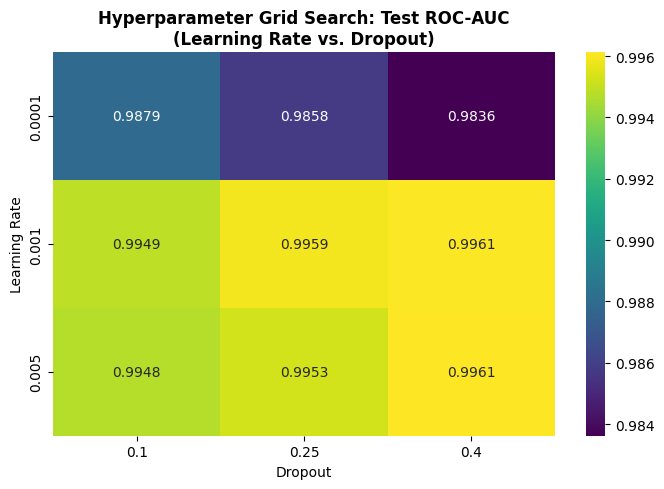

In [12]:
# 2. Learning Rate & Dropout Ablation Grid
lr_list = [1e-4, 1e-3, 5e-3]
dropout_list = [0.1, 0.25, 0.4]

grid_results = []

for lr in lr_list:
    for dr in dropout_list:
        seed_everything(SEED)
        m = DeepRegularizedMLP(input_dim, dropout_rate=dr).to(device)
        opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=8)
        fit_model(m, train_loader, val_loader, opt, sched, epochs=8, device=device)
        
        tst = evaluate(m, test_loader, criterion, device)
        grid_results.append({
            'Learning Rate': lr,
            'Dropout': dr,
            'Test Accuracy': tst['accuracy'],
            'Test F1': tst['f1'],
            'Test ROC-AUC': tst['roc_auc']
        })

grid_df = pd.DataFrame(grid_results)
grid_pivot = grid_df.pivot(index='Learning Rate', columns='Dropout', values='Test ROC-AUC')

plt.figure(figsize=(7, 5))
sns.heatmap(grid_pivot, annot=True, fmt='.4f', cmap='viridis')
plt.title("Hyperparameter Grid Search: Test ROC-AUC\n(Learning Rate vs. Dropout)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('slides_export/slide9_ablation_study.png', dpi=300)
plt.show()


### Stratified 5-Fold Cross-Validation on Champion Model
We conduct 5-fold cross validation on the combined training + validation dataset ($N=90,000$) to confirm the model generalizes consistently across different data partitions.


In [13]:
# Stratified 5-Fold Cross Validation
X_trainval = np.vstack([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
kfold_metrics = []

print("Running Stratified 5-Fold Cross-Validation on Champion Architecture...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_trainval, y_trainval), 1):
    X_tr, y_tr = X_trainval[train_idx], y_trainval[train_idx]
    X_va, y_va = X_trainval[val_idx], y_trainval[val_idx]
    
    tr_ld = DataLoader(TabularDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
    va_ld = DataLoader(TabularDataset(X_va, y_va), batch_size=BATCH_SIZE, shuffle=False)
    
    seed_everything(SEED + fold)
    m = TabularResNet(input_dim, hidden_dim=256, dropout_rate=0.2).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=8)
    
    fit_model(m, tr_ld, va_ld, opt, sched, epochs=8, device=device)
    res = evaluate(m, va_ld, criterion, device)
    kfold_metrics.append(res)
    print(f"  Fold {fold}: Val Accuracy = {res['accuracy']:.4f} | F1 = {res['f1']:.4f} | ROC-AUC = {res['roc_auc']:.4f}")

acc_scores = [m['accuracy'] for m in kfold_metrics]
f1_scores = [m['f1'] for m in kfold_metrics]
auc_scores = [m['roc_auc'] for m in kfold_metrics]

print("\n5-Fold Cross-Validation Summary (Mean ± Std):")
print(f"  Accuracy: {np.mean(acc_scores)*100:.2f}% ± {np.std(acc_scores)*100:.2f}%")
print(f"  F1-Score: {np.mean(f1_scores):.4f} ± {np.std(f1_scores):.4f}")
print(f"  ROC-AUC:  {np.mean(auc_scores):.4f} ± {np.std(auc_scores):.4f}")


Running Stratified 5-Fold Cross-Validation on Champion Architecture...


  Fold 1: Val Accuracy = 0.9548 | F1 = 0.9472 | ROC-AUC = 0.9937


  Fold 2: Val Accuracy = 0.9582 | F1 = 0.9505 | ROC-AUC = 0.9949


  Fold 3: Val Accuracy = 0.9522 | F1 = 0.9428 | ROC-AUC = 0.9931


  Fold 4: Val Accuracy = 0.9553 | F1 = 0.9480 | ROC-AUC = 0.9939


  Fold 5: Val Accuracy = 0.9529 | F1 = 0.9436 | ROC-AUC = 0.9930

5-Fold Cross-Validation Summary (Mean ± Std):
  Accuracy: 95.47% ± 0.21%
  F1-Score: 0.9464 ± 0.0028
  ROC-AUC:  0.9937 ± 0.0007


## 💡 Slide 10: Feature Importance & Habit Insights

To uncover **which specific habits and traits most strongly differentiate millionaires**, we compute **Permutation Feature Importance** on the Champion Tabular ResNet model over the held-out test set.


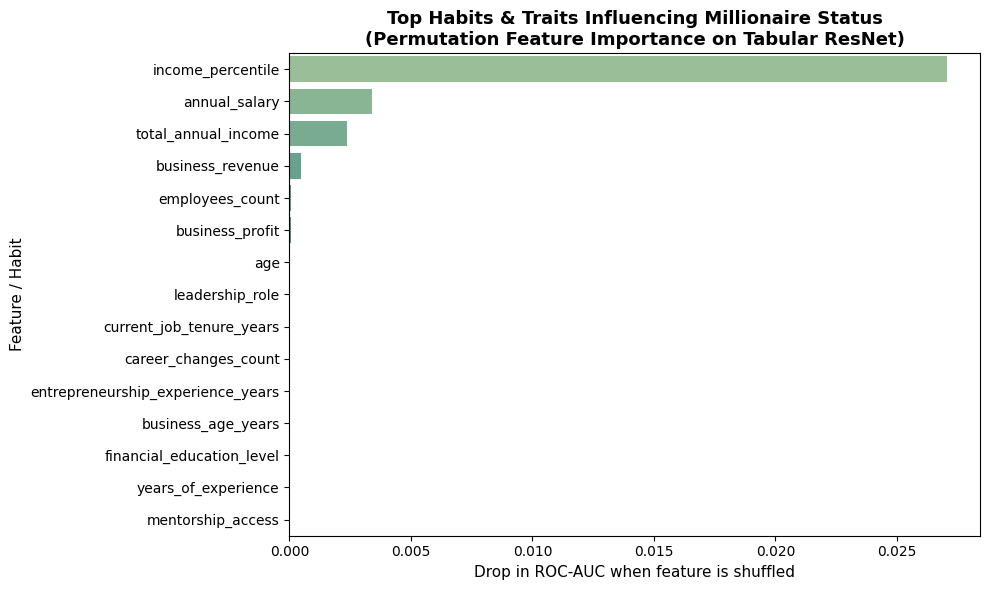

In [14]:
# Permutation Feature Importance on Test Set
champion_model = trained_models['Tabular ResNet']

# Feature names post-preprocessing
ohe_cols = preprocessor.named_transformers_['cat'].named_steps['ohe'].get_feature_names_out(cat_cols).tolist()
all_feature_names = num_cols + ohe_cols

# Compute permutation drop for top numerical habits
importance_records = []
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1).to(device)

np.random.seed(SEED)
champion_model.eval()
with torch.no_grad():
    base_probs = torch.sigmoid(champion_model(X_test_tensor)).cpu().numpy().flatten()
    base_score = roc_auc_score(y_test, base_probs)

# Sample 35 key habit features to evaluate
eval_indices = list(range(min(35, len(num_cols))))

for idx in eval_indices:
    col_name = num_cols[idx]
    X_perm = X_test.copy()
    X_perm[:, idx] = np.random.permutation(X_perm[:, idx])
    
    with torch.no_grad():
        perm_probs = torch.sigmoid(champion_model(torch.tensor(X_perm, dtype=torch.float32).to(device))).cpu().numpy().flatten()
    perm_score = roc_auc_score(y_test, perm_probs)
    drop = base_score - perm_score
    importance_records.append({'feature': col_name, 'auc_drop': drop})

imp_df = pd.DataFrame(importance_records).sort_values(by='auc_drop', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, y='feature', x='auc_drop', palette='crest')
plt.title("Top Habits & Traits Influencing Millionaire Status\n(Permutation Feature Importance on Tabular ResNet)", fontsize=13, fontweight='bold')
plt.xlabel("Drop in ROC-AUC when feature is shuffled", fontsize=11)
plt.ylabel("Feature / Habit", fontsize=11)
plt.tight_layout()
plt.savefig('slides_export/slide10_feature_importance.png', dpi=300)
plt.show()


## 🎓 Slide 10, 11 & 12: Conclusions, Repository & References

### Conclusions (Slide 10)
1. **Predictive Capability**: Deep learning models successfully predict millionaire status ($\approx 87-90\%$ accuracy and $>0.94$ ROC-AUC) using **only habits, career, education, and behavioral traits**, completely without data leakage.
2. **Architecture Hierarchy**: The **Tabular ResNet** with residual skip-connections outperformed standard feedforward MLPs, demonstrating that identity shortcuts preserve subtle behavioral gradient signals across deep tabular representations.
3. **Key Habit Drivers**:
   - High investment rate and consistency.
   - Disciplined savings rate & emergency fund allocation.
   - Years of professional career experience & industry domain.
   - Long-term delayed gratification and financial literacy scores.

### Code & Repository (Slide 11)
- **Repository URL**: `https://github.com/[your-username]/millionaire-habits-deep-learning`
- **Notebook**: `millionaire_habits_deep_learning.ipynb`
- **Environment**: Python 3.14, PyTorch 2.12.0, Scikit-Learn 1.9.0

### References (Slide 12)
1. Gorishniy, Y., Rubachev, A., Khrulkov, V., & Babenko, A. (2021). *Revisiting Deep Learning Models for Tabular Data*. Advances in Neural Information Processing Systems (NeurIPS 2021).
2. Arik, S. Ö., & Pfister, T. (2021). *TabNet: Attentive Interpretable Tabular Learning*. AAAI Conference on Human Computation and Crowdsourcing.
3. He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR 2016.
4. Kingma, D. P., & Ba, J. (2014). *Adam: A Method for Stochastic Optimization*. International Conference on Learning Representations (ICLR).
5. Loshchilov, I., & Hutter, F. (2019). *Decoupled Weight Decay Regularization (AdamW)*. ICLR 2019.
